#Setup

In [2]:
!pip install -q gymnasium stable-baselines3 pygame numpy matplotlib

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import stable_baselines3 as sb3
from gymnasium.utils import seeding
from gymnasium.utils.env_checker import check_env

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#RL loop - random agent on frozenlake

In [4]:
env = gym.make("FrozenLake-v1", is_slippery = False, render_mode="ansi")

print(env.observation_space)
print(env.action_space)

Discrete(16)
Discrete(4)


In [16]:
#obs space
obs, info = env.reset(seed=0)

done = False
steps, total_reward = 0,0

while not done:
  action = env.action_space.sample()
  obs,reward,terminated,truncated,info = env.step(action)
  done = terminated or truncated
  total_reward += reward
  steps+=1

  print(f"steps={steps}, total reward={total_reward}")

steps=1, total reward=0
steps=2, total reward=0
steps=3, total reward=0
steps=4, total reward=0
steps=5, total reward=0
steps=6, total reward=0
steps=7, total reward=0
steps=8, total reward=0
steps=9, total reward=0
steps=10, total reward=0
steps=11, total reward=0
steps=12, total reward=0
steps=13, total reward=0
steps=14, total reward=0
steps=15, total reward=0
steps=16, total reward=0
steps=17, total reward=0


#Q-learning

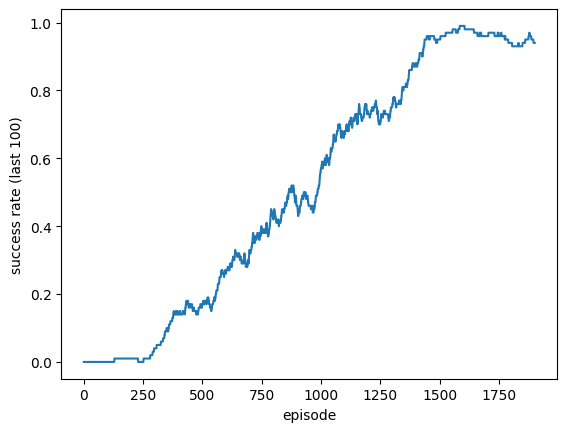

[[0.74 0.77 0.7  0.74]
 [0.74 0.   0.66 0.7 ]
 [0.7  0.61 0.55 0.66]
 [0.64 0.   0.23 0.37]
 [0.77 0.81 0.   0.74]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.66]
 [0.   0.   0.   0.  ]
 [0.81 0.   0.86 0.77]
 [0.81 0.9  0.9  0.  ]
 [0.86 0.95 0.   0.63]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.9  0.95 0.86]
 [0.9  0.95 1.   0.9 ]
 [0.   0.   0.   0.  ]]
[['↓' '←' '←' '←']
 ['↓' '←' '↑' '←']
 ['→' '↓' '↓' '←']
 ['←' '→' '→' '←']]


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

env = gym.make("FrozenLake-v1", is_slippery=False, render_mode="ansi")

def epsilon_greedy(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))     # explore
    return int(np.argmax(Q[state]))               # exploit

def train_q_learning(env, episodes=2000, alpha=0.5, gamma=0.95,
                     eps_start=1.0, eps_end=0.05, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    rewards = []
    for ep in range(episodes):
        epsilon = max(eps_end, eps_start - (eps_start - eps_end) * ep / (0.8 * episodes))
        state, _ = env.reset(seed=seed + ep)
        done, ep_reward = False, 0.0
        while not done:
            action = epsilon_greedy(Q, state, epsilon, rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            target = reward + (0.0 if terminated else gamma * np.max(Q[next_state]))
            Q[state, action] += alpha * (target - Q[state, action])
            state = next_state
            ep_reward += reward
            done = terminated or truncated
        rewards.append(ep_reward)
    return Q, rewards

Q, rewards = train_q_learning(env)                 # creates Q and rewards

# learning curve
moving_avg = np.convolve(rewards, np.ones(100) / 100, mode="valid")
plt.plot(moving_avg); plt.xlabel("episode"); plt.ylabel("success rate (last 100)"); plt.show()

# learned policy
print(np.round(Q, 2))
print(np.array(["←", "↓", "→", "↑"])[np.argmax(Q, axis=1)].reshape(4, 4))

#Part 3 own environment - tank level

In [41]:
class tanklevel(gym.Env):
  def __init__(self, setpoint = 0.5, dt = 0.1, k_out = 0.8, max_steps = 200, noise = 0.0):
    super().__init__()
    self.setpoint = setpoint
    self.dt = dt
    self.k_out = k_out
    self.max_steps = max_steps
    self.noise = noise

    #observation space
    self.observation_space = spaces.Box(
        low = np.array([0.0,-1.0], dtype = np.float32),
        high = np.array([1.0,1.0], dtype = np.float32),
    )

    #action space
    self.action_space = spaces.Box(low = -1.0, high = 1.0, shape = (1,), dtype = np.float32)

  def _get_obs(self):
    measured = self.level + self.noise * self.np_random.normal()
    measured = float(np.clip(measured, 0.0, 1.0))
    return np.array([measured, self.setpoint - measured], dtype= np.float32)

  def reset(self, seed=None, options = None):
    super().reset(seed=seed)
    self.level = float(self.np_random.uniform(0.05,0.95))
    self.steps = 0
    info = {}
    return self._get_obs(), info

  def step(self, action):
    a = float(np.clip(action[0], -1.0, 1.0))
    u = (a+1.0)/2.0

    dhdt = u-self.k_out * np.sqrt(max(self.level, 0.0))
    self.level += self.dt * dhdt
    self.steps += 1

    error = self.setpoint - self.level
    reward = -error ** 2 - 0.01 * u ** 2

    termrinated = self.level <= 0.0 or self.level >= 1.0

    if terminated:
      reward -=10
    self.level = float(np.clip(self.level, 0.0, 1.0))
    truncated = self.steps >= self.max_steps

    return self._get_obs(), reward, terminated, truncated, {"u": u}

In [43]:
    env = tanklevel()
    check_env(env)
    print("pass")

    obs, info = env.reset(seed= 0)
    for t in range(5):
      action = env.action_space.sample()
      obs, reward, terminated, truncated, info = env.step(action)
      print(f"t={t} action={action[0]:+.2f} u={info['u']:.2f} obs={obs} reward={reward:.4f}")

pass
t=0 action=-0.89 u=0.05 obs=[ 0.5654899  -0.06548989] reward=-10.0043
t=1 action=-0.56 u=0.22 obs=[ 0.52736664 -0.02736663] reward=-10.0012
t=2 action=-0.63 u=0.18 obs=[0.4877078  0.01229221] reward=-10.0005
t=3 action=-0.65 u=0.18 obs=[0.4494295  0.05057048] reward=-10.0029
t=4 action=+0.62 u=0.81 obs=[0.47700736 0.02299263] reward=-10.0071


/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


#Train PPo with Stable-baseline3

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

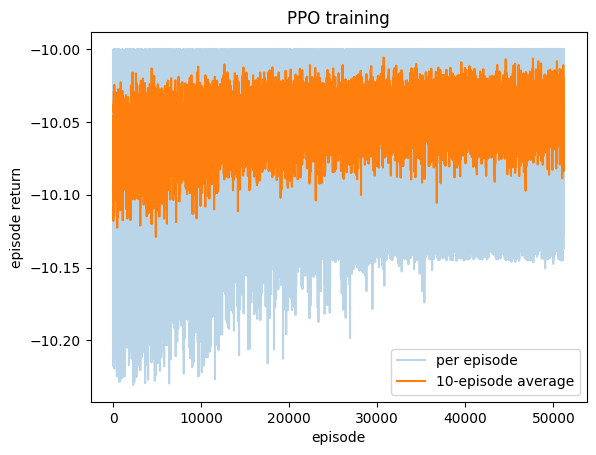

In [48]:
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
train_env = Monitor(tanklevel())

ppo_model = PPO("MlpPolicy", train_env, verbose = 0, seed=0)
ppo_model.learn(total_timesteps = 50_000, progress_bar = True)

action, _ = ppo_model.predict(obs,deterministic = True)

ep_rewards = train_env.get_episode_rewards()
smooth = np.convolve(ep_rewards, np.ones(10) / 10, mode="valid")
plt.plot(ep_rewards, alpha=0.3, label="per episode")
plt.plot(smooth, label="10-episode average")
plt.xlabel("episode"); plt.ylabel("episode return"); plt.legend(); plt.title("PPO training")
plt.show()

#PID Baseline and fair comparison

In [ ]:
def __call__(self, error):
  deriv = 0.0 if self.prev_error is None else (error - self.prev_error)
  self.prev_error = error
  u = self.kp * error + self.kl * (self.integral + error * self.dt) + self.kd * deriv
  if self.u_min < u < self.u_max:
    self. integral += error * self.dt
  return min(max(u,self.umin), self.u_max)

